# 7. Apprentissage semi-supervisé : profil de résistance

**Question** : les soudures dont on ne connaît **pas les quatre propriétés de traction** (on connaît leur composition et leur procédé, mais pas leur profil) permettent-elles de mieux prédire le profil de résistance que le modèle supervisé retenu par l'équipe ?

Le sujet demande d'appliquer **au moins une méthode semi-supervisée en justifiant son choix et sa pertinence**. On applique les **trois familles de méthodes vues en cours** et on compare chaque méthode au **modèle supervisé retenu par l'équipe** dans le notebook 5, avec exactement le même protocole.

**Cible** : le **profil de résistance** construit dans les notebooks 4 et 5 : les quatre propriétés de traction (limite d'élasticité, résistance maximale, allongement, striction) sont standardisées, résumées par une ACP à 2 composantes, puis regroupées en **2 profils par K-means** : **0 = résistance modérée** (plus ductile) et **1 = résistance élevée** (plus résistante, moins ductile). La règle est apprise sur le train du notebook 5 uniquement. Seules les soudures qui ont **les quatre propriétés** peuvent recevoir un profil : les autres sont **non étiquetées** et forment les données $U$ du semi-supervisé.

**Ce qui est repris du notebook 5 (pour que la comparaison soit juste)**
- le **même découpage train / test** (relu dans `05_reporting/profil_resistance/split_train_test.csv`) : le test n'est utilisé qu'une seule fois, à la fin ;
- la **même imputation métier** (`WeldImputer`) et la même variable construite (`CE_IIW`) ;
- le **modèle supervisé retenu par l'équipe** (relu dans `modele_retenu.json`), qui sert de modèle de base au self-training et de référence ;
- la même validation croisée groupée par publication (`StratifiedGroupKFold`, 5 plis, `random_state=42`).

Toutes les fonctions sont dans `utils_semi_supervise.py`, déjà utilisé par le notebook 6 (`Charpy conforme`) : les deux notebooks suivent exactement la même démarche.

## Rappel : les trois familles de méthodes vues en cours

On dispose de $m$ exemples étiquetés $S = \{(x_i, y_i)\}_{i=1}^{m}$ et de $u$ exemples non étiquetés $U = \{x_i\}_{i=m+1}^{m+u}$. On cherche une fonction $h : x \mapsto y$ meilleure que celle apprise sur $S$ seul, en exploitant la structure de $U$.

| Famille | Principe | Hypothèse du cours | Méthodes testées |
|---|---|---|---|
| **Discriminante** (self-training) | Un modèle supervisé prédit $U$ ; les prédictions les plus **sûres** deviennent des pseudo-étiquettes ; on ré-entraîne et on itère (« version discriminante de CEM ») | Séparation en zone de faible densité | Self-training classique · Self-training équilibré par classe |
| **Graphe** (label spreading) | Graphe des $k$ plus proches voisins sur $S \cup U$ ; les étiquettes diffusent vers les voisins : $\tilde Y^* = (S + \lambda(D - W))^{-1} S Y$ | Lissité / variété | Label spreading |
| **Générative** (CEM semi-supervisé) | Une loi gaussienne par classe ; étape E (probabilités des non-étiquetées), C (affectation), M (ré-estimation sur $S \cup U$) | Lissité / clusters | CEM semi-supervisé |

**Référence** : toutes les méthodes sont comparées au modèle retenu par l'équipe (notebook 5), entraîné sur les mêmes soudures étiquetées. La question posée est donc pratique : *une méthode semi-supervisée fait-elle mieux que notre meilleur modèle supervisé ?*

**Ces méthodes ne fonctionnent que si leurs hypothèses sont vérifiées** (Singh, Nowak & Zhu, 2008 ; Oliver et al., 2018) : on les teste en section 2 avant d'appliquer les méthodes.

## 0. Imports et paramètres

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import utils_semi_supervise as ssl

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")

RANDOM_STATE = 42                 # même graine que les notebooks 3 et 5
N_FOLDS = 5                       # même nombre de plis
FRACTIONS = [0.1, 0.25, 0.5, 1.0] # part des étiquettes d'entraînement conservées (courbe d'apprentissage)
N_TIRAGES = 3                     # tirages par fraction < 100 % (lisse le bruit de la courbe)
N_BOOT = 500                      # rééchantillonnages bootstrap
METRIQUE = "Accuracy_ponderee"    # métrique principale (justification en section 3)

CIBLE = "Profil de résistance"
METHODE_REF = "A_sans_selection"  # le semi-supervisé utilise toutes les variables, comme la méthode A

P_DONNEES = Path("..") / "1. Données"
P_REF = P_DONNEES / "05_reporting" / "profil_resistance"
P_SORTIE = P_DONNEES / "05_reporting" / "semi_supervise" / "profil_resistance"
P_FIG = Path("..") / "3. Résultats" / "figures"
P_FIG.mkdir(parents=True, exist_ok=True)

def savefig(nom):
    plt.savefig(P_FIG / f"ssl_profil_{nom}.png", dpi=150, bbox_inches="tight")

## 1. Données

- Entrées : les mêmes que le notebook 5. Les quatre propriétés de traction sont retirées (elles **construisent** le profil : les garder donnerait la réponse), ainsi que `Charpy conforme` (une cible ne doit pas servir à en prédire une autre).
- **Non-étiquetées $U$** : les soudures auxquelles il manque au moins une des quatre propriétés. Celles qui viennent d'une **publication du test** sont retirées : même sans étiquette, leurs entrées décrivent les soudures du test, et le graphe ou le self-training pourraient s'en servir pour « préparer » le test.

In [2]:
df = pd.read_csv(P_DONNEES / "02_intermediate" / "welddb_processed_vf.csv", sep=";")
corresp = pd.read_csv(P_DONNEES / "02_intermediate" / "correspondance_between_names_units_vf.csv", sep=";")
TARGETS = corresp.loc[corresp["Role"] == "Quality indicator", "Feature"].tolist()

from utils_pipeline import QUALITY_VARIABLES        # les 4 propriétés de traction
masque_profil = df[QUALITY_VARIABLES].notna().all(axis=1)
COLONNES_A_RETIRER = TARGETS + ["Charpy temperature", "Charpy impact toughness"]
jeux = ssl.preparer_jeux(df, masque_etiquete=masque_profil,
                         chemin_split=P_REF / "split_train_test.csv", col_cible="profil",
                         colonnes_a_retirer=COLONNES_A_RETIRER)

y_tr = jeux["y_lab"].iloc[jeux["train_idx"]]
y_te = jeux["y_lab"].iloc[jeux["test_idx"]]
print(f"Entrées : {jeux['X_lab'].shape[1]} variables")
print(f"Étiquetées : {len(jeux['y_lab'])}  (train {len(y_tr)}, test {len(y_te)}) — split relu du notebook 5")
print(f"  train : {y_tr.value_counts().to_dict()}   test : {y_te.value_counts().to_dict()}   (1 = résistance élevée)")
print(f"Non étiquetées utilisables : {len(jeux['X_unl'])}  ({jeux['n_unl_exclues_test']} exclues car issues d'une publication du test)")
print(f"Publications : {jeux['g_lab'].nunique()} étiquetées, "
      f"{jeux['g_lab'][jeux['y_lab'] == 1].nunique()} contiennent des soudures à résistance élevée")
print(f"Non-étiquetées ayant au moins une des 4 propriétés : {int(df.loc[~masque_profil, QUALITY_VARIABLES].notna().any(axis=1).sum())} sur {int((~masque_profil).sum())}")

Entrées : 25 variables
Étiquetées : 650  (train 523, test 127) — split relu du notebook 5
  train : {0: 340, 1: 183}   test : {0: 83, 1: 44}   (1 = résistance élevée)
Non étiquetées utilisables : 873  (115 exclues car issues d'une publication du test)
Publications : 82 étiquetées, 47 contiennent des soudures à résistance élevée
Non-étiquetées ayant au moins une des 4 propriétés : 149 sur 988


In [3]:
# Modèle supervisé retenu par l'équipe (notebook 5, méthode A) : référence et modèle de base du self-training
ref = ssl.charger_reference(P_REF / METHODE_REF / "modele_retenu.json")
NOM_REF = ref["modele_retenu"]
modele_ref = ssl.modele_depuis_json(NOM_REF, ref["hyperparametres_retenu"])
print(f"Modèle retenu par l'équipe : {NOM_REF}  {ref['hyperparametres_retenu']}")
print(f"Score de test publié (notebook 5) : " + ", ".join(f"{k} = {v:.3f}" for k, v in ref["score_test"].items()))

Modèle retenu par l'équipe : Arbre  {'max_depth': 2, 'min_samples_leaf': 20}
Score de test publié (notebook 5) : Accuracy = 0.827, Accuracy_ponderee = 0.846, F1 = 0.784, Precision = 0.690, Recall = 0.909, ROC_AUC = 0.907, LogLoss = 0.383


## 2. Les hypothèses du semi-supervisé sont-elles vérifiées ?

Le semi-supervisé n'apporte quelque chose que si les non-étiquetées **renseignent sur la forme du problème** (vu en cours). Quatre vérifications, toutes faites sur le **train** uniquement (le test n'est pas regardé, sauf en 2.4 où l'on n'utilise que ses entrées, jamais ses étiquettes) :

| Vérification | Hypothèse testée | Ce qu'on attend si l'hypothèse tient |
|---|---|---|
| 2.1 Publications communes | $U$ et $S$ viennent de la même « population » | une grande part de $U$ vient de publications qui ont aussi des étiquetées |
| 2.2 Superposition (ACP) | $U$ est dans la même zone de l'espace que $S$ | les nuages se recouvrent |
| 2.3 Lissité | deux soudures proches ont la même classe | accord avec les voisins nettement supérieur au hasard, **y compris avec des voisins d'autres publications** |
| 2.4 Ponts | $U$ « comble les trous » entre train et test | les soudures du test sont plus proches d'une non-étiquetée que d'une étiquetée |

In [4]:
X_tr = jeux["X_lab"].iloc[jeux["train_idx"]]
prep_h = ssl.PretraitementSSL().fit(pd.concat([X_tr, jeux["X_unl"]], ignore_index=True))
Z_tr, Z_unl = prep_h.transform(X_tr), prep_h.transform(jeux["X_unl"])
Z_te = prep_h.transform(jeux["X_lab"].iloc[jeux["test_idx"]])     # entrées du test seulement (2.4)
g_tr = jeux["g_lab"].iloc[jeux["train_idx"]]

hyp = {}
hyp["part de U issue de publications étiquetées"] = ssl.part_sources_communes(g_tr, jeux["g_unl"])
print(f"2.1  {hyp['part de U issue de publications étiquetées']:.0%} des non-étiquetées viennent d'une publication qui a aussi des soudures étiquetées (train)")

2.1  57% des non-étiquetées viennent d'une publication qui a aussi des soudures étiquetées (train)


In [5]:
fig, ax = plt.subplots(figsize=(8, 6))
ssl.figure_superposition_acp(Z_tr, Z_unl, y_tr, "2.2  ACP des entrées : étiquetées (train) et non étiquetées",
                             noms_classes=("modérée", "élevée"), ax=ax)
plt.tight_layout(); savefig("acp_superposition"); plt.show()

<Figure size 800x600 with 1 Axes>

In [6]:
lissite = ssl.test_lissite(Z_tr, y_tr, g_tr, k=5)
ponts = ssl.test_ponts(Z_tr, Z_unl, Z_te)
hyp.update(lissite.to_dict()); hyp.update(ponts.to_dict())
print("2.3  Lissité"); print(lissite.round(3).to_string())
print("\n2.4  Ponts"); print(ponts.round(3).to_string())
hypotheses = pd.Series(hyp)

2.3  Lissité
accord attendu par hasard                                       0.545
accord avec les 5 plus proches voisins                          0.820
accord avec les 5 plus proches voisins d'AUTRES publications    0.718

2.4  Ponts
distance médiane test -> étiquetée la plus proche                     1.275
distance médiane test -> soudure la plus proche (étiquetée ou non)    1.226
part du test dont la plus proche voisine est NON étiquetée            0.283


### 2.5 Bilan : hypothèses moins bien vérifiées que pour `Charpy conforme`



- **2.1 Publications communes : 57 %.** Un peu plus de la moitié des non-étiquetées viennent d'études qui ont aussi des soudures étiquetées. Les autres décrivent des aciers sans aucun essai de traction complet. À noter : seules 149 des 988 non-étiquetées ont au moins une des quatre propriétés ; les autres n'ont **aucun** essai de traction.
- **2.2 Superposition : partielle, et les deux profils sont mélangés.** La zone dense des métaux C-Mn (en bas à gauche) contient à la fois des soudures « modérées » et « élevées » : dans l'espace de **toutes** les entrées, les deux profils ne forment pas de groupes séparés. Une grande zone à droite (aciers très alliés, Z1 de 4 à 8) ne contient presque que des non-étiquetées.
- **2.3 Lissité : vérifiée, mais nettement plus faible que pour Charpy.** 82 % d'accord avec les 5 plus proches voisins contre 55 % attendus par hasard, mais seulement **72 % avec des voisins d'autres publications** (85 % pour Charpy). Une part importante de la « lissité » vient donc de soudures voisines issues de la **même** étude.
- **2.4 Ponts : faibles.** Pour 28 % des soudures du test, la plus proche voisine est une non-étiquetée ; la distance médiane ne baisse que de 1,28 à 1,23.

**Conséquence attendue** : le profil de résistance dépend surtout de **quelques variables** (la teneur en éléments d'alliage, voir 5.1), alors que les méthodes à base de distances (graphe, gaussiennes) donnent le même poids à toutes les entrées. On s'attend donc à ce que ces méthodes fonctionnent mal, et à ce que le gain semi-supervisé soit au mieux faible.

## 3. Protocole d'évaluation

**Principe** : on évalue **toujours sur de vraies étiquettes**, et chaque méthode semi-supervisée est comparée au **modèle retenu par l'équipe**, entraîné sur les mêmes soudures étiquetées.

| Étape | Choix | Justification |
|---|---|---|
| Découpage | Validation croisée **sur le train du notebook 5**, `StratifiedGroupKFold` (5 plis, graine 42) ; le test n'est utilisé qu'en section 6 | mêmes conditions que le supervisé ; une publication est entièrement d'un côté (sinon le modèle reconnaît la « signature » d'une étude) |
| Non-étiquetées | $U$ = non-étiquetées hors publications du pli de validation (et du test) | cas réaliste d'une soudure issue d'une étude jamais vue |
| Prétraitement | `WeldImputer` + `CE_IIW` + standardisation + one-hot, appris sur $S \cup U$ pour **toutes** les méthodes | imputation de l'équipe ; la standardisation est indispensable aux méthodes à base de distances (graphe, gaussiennes) et sans effet sur les arbres ; l'apprendre sur $S \cup U$ pour tout le monde isole l'effet de l'**algorithme** |
| Courbe d'apprentissage | on garde 10 %, 25 %, 50 %, 100 % des étiquettes de $S$ ; les autres sont **cachées** et rejoignent $U$ ; **3 tirages** par fraction | le semi-supervisé est censé aider surtout quand les étiquettes sont rares ; plusieurs tirages lissent le bruit (à 10 %, chaque pli ne garde qu'une trentaine de soudures étiquetées) |
| Métriques | calculées sur les **prédictions hors-pli regroupées** des 5 plis (*pooled*) | un pli peut contenir peu de soudures d'une classe : un score par pli serait très instable (Forman & Scholz, 2010) |
| Incertitude | **bootstrap sur les publications** ; gain semi-supervisé − supervisé par **bootstrap apparié** | les soudures d'une même publication ne sont pas indépendantes ; l'appariement (mêmes publications tirées pour les deux méthodes) annule le bruit commun |

**Métrique principale : l'accuracy pondérée (*balanced accuracy*)**, moyenne des rappels des deux classes (0,5 = hasard), comme dans le notebook 6 pour que les deux études semi-supervisées soient comparables. Ici, la classe 1 (« résistance élevée ») est **minoritaire (≈ 35 %)** : le F1 de la classe 1, utilisé par le notebook 5, est donc lui aussi pertinent et il est affiché, ainsi que le F1 de la classe 0 et l'AUC.

**Règle de choix, fixée avant de voir les résultats** :
1. le modèle semi-supervisé **retenu** est celui qui a la meilleure accuracy pondérée en **validation croisée imbriquée** (hyperparamètres réglés automatiquement, section 5.3) avec 100 % des étiquettes ;
2. on ne le déclare **utile** que si la borne basse de l'IC à 95 % de son gain apparié sur le modèle de l'équipe est **positive**.

## 4. Méthodes

Le code est dans `utils_semi_supervise.py` (section 4).

**Self-training classique** (`SelfTrainingClassifier`, seuil 0,9) : le modèle retenu par l'équipe prédit $U$, les prédictions de probabilité ≥ 0,9 deviennent des pseudo-étiquettes, on ré-entraîne, jusqu'à 10 fois.

**Self-training équilibré** (`SelfTrainingEquilibre`, codé pour ce projet) : le self-training classique risque de n'ajouter que des pseudo-étiquettes de la classe majoritaire, les plus sûres, et de renforcer son propre biais (*biais de confirmation* ; c'est ce qui avait été observé sur `Charpy conforme` avec sa première définition). Ici, à chaque itération, on ajoute **pour chaque classe** les soudures les plus sûrement prédites dans cette classe (probabilité ≥ 0,7), **en respectant la proportion des classes** des vraies étiquettes (10 % de $U$ par itération).

**Label spreading** (`SafeLabelSpreading`) : graphe des 10 plus proches voisins, $\alpha = 0{,}2$. Une soudure sans aucun voisin informé a une probabilité 0/0 : on lui attribue la proportion des classes au lieu de la classe 0 par défaut (qui fausserait les scores).

**CEM semi-supervisé** (`SemiSupervisedCEM`, algorithme du cours) : une gaussienne par classe, dans l'espace des **10 premières composantes de l'ACP** (hypothèse de variété : estimer une covariance en ~40 dimensions avec ~200 soudures à résistance élevée serait instable), covariances diagonales.

**Hyperparamètres** : en section 5, valeurs usuelles fixées à l'avance (ci-dessus), pour comparer les méthodes « telles quelles » et tracer la courbe d'apprentissage ; en section 5.3, ils sont **réglés par validation croisée imbriquée**, et ce sont ces versions réglées qui servent au choix du modèle et au test final.

In [7]:
methodes, paires = ssl.methodes_classification(modele_ref, NOM_REF, n_voisins=10, n_composantes=10)
NOM_REF_LONG = paires[0][1]
pd.DataFrame([(f, s_) for f, _, s_ in paires], columns=["famille", "méthode semi-supervisée"]).assign(**{"comparée à": NOM_REF_LONG})

,famille,méthode semi-supervisée,comparée à
0,Discriminante (self-training),Self-training classique,"Arbre (supervisé, retenu par l'équipe)"
1,Discriminante (self-training),Self-training équilibré,"Arbre (supervisé, retenu par l'équipe)"
2,Graphe,Label spreading,"Arbre (supervisé, retenu par l'équipe)"
3,Générative,CEM semi-supervisé,"Arbre (supervisé, retenu par l'équipe)"


## 5. Résultats en validation croisée

In [8]:
preds_cv = ssl.evaluer_ssl_cv(jeux, methodes, fractions=FRACTIONS, n_tirages=N_TIRAGES,
                              n_folds=N_FOLDS, random_state=RANDOM_STATE)
scores = ssl.scores_regroupes(preds_cv)

pli 1/5 terminé


pli 2/5 terminé


pli 3/5 terminé


pli 4/5 terminé


pli 5/5 terminé


In [9]:
# Synthèse avec 100 % des étiquettes
METRIQUES_AFF = ["Accuracy_ponderee", "F1", "F1_classe_0", "F1_macro", "Recall", "ROC_AUC"]
s100 = scores.xs(1.0, level="fraction")[METRIQUES_AFF].copy()
ic = {m: ssl.ic_bootstrap(preds_cv[(preds_cv["methode"] == m) & (preds_cv["fraction"] == 1.0)], METRIQUE, N_BOOT)
      for m in s100.index}
s100[f"{METRIQUE} IC95"] = [f"[{ic[m][0]:.2f} ; {ic[m][1]:.2f}]" for m in s100.index]
print("Validation croisée, 100 % des étiquettes (prédictions hors-pli regroupées ; IC95 bootstrap sur les publications)")
s100.round(3)

Validation croisée, 100 % des étiquettes (prédictions hors-pli regroupées ; IC95 bootstrap sur les publications)


,Accuracy_ponderee,F1,F1_classe_0,F1_macro,Recall,ROC_AUC,Accuracy_ponderee IC95
methode,,,,,,,
"Arbre (supervisé, retenu par l'équipe)",0.847,0.800,0.891,0.845,0.809,0.848,[0.79 ; 0.89]
Self-training classique,0.798,0.743,0.885,0.814,0.656,0.833,[0.72 ; 0.88]
Self-training équilibré,0.847,0.800,0.891,0.845,0.809,0.853,[0.79 ; 0.89]
Label spreading,0.592,0.411,0.772,0.591,0.328,0.722,[0.52 ; 0.67]
CEM semi-supervisé,0.715,0.634,0.784,0.709,0.672,0.746,[0.62 ; 0.80]


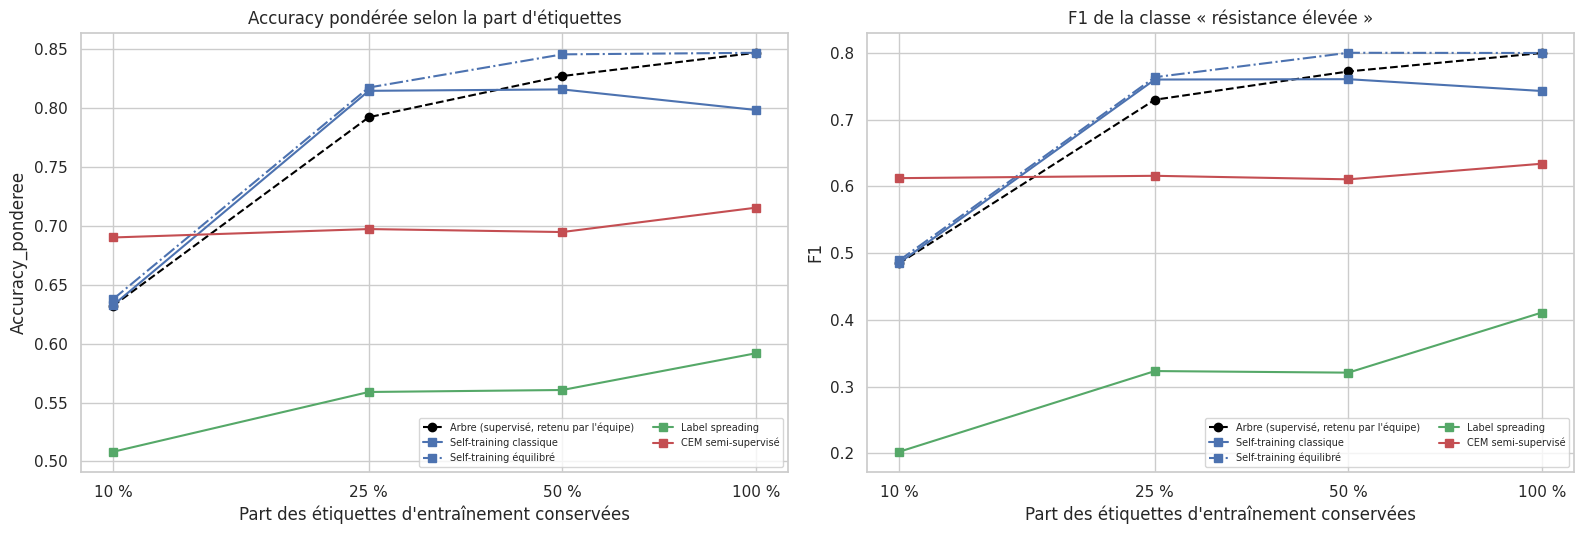

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
ssl.courbe_apprentissage(scores, paires, METRIQUE, "Accuracy pondérée selon la part d'étiquettes", ax=axes[0])
ssl.courbe_apprentissage(scores, paires, "F1", "F1 de la classe « résistance élevée »", ax=axes[1])
plt.tight_layout(); savefig("courbe_apprentissage"); plt.show()

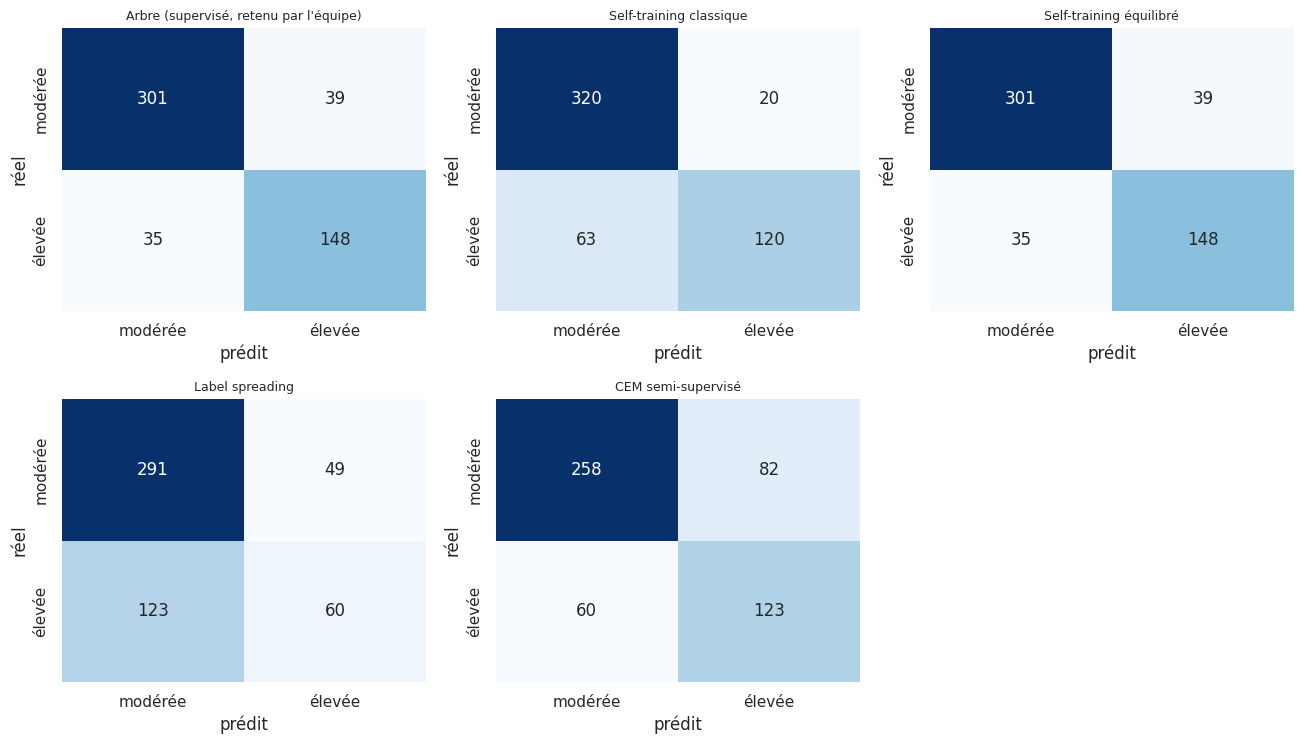

In [11]:
ssl.matrices_confusion(preds_cv, list(methodes), noms_classes=("modérée", "élevée"))
savefig("confusion_cv"); plt.show()

In [12]:
gains = ssl.tableau_gains(preds_cv, paires, METRIQUE, FRACTIONS, n_boot=N_BOOT)
print("Gain en accuracy pondérée (semi-supervisé − modèle de l'équipe), bootstrap apparié sur les publications")
gains.pivot_table(index=["famille", "semi-supervisé"], columns="fraction", values="gain").round(3)

Gain en accuracy pondérée (semi-supervisé − modèle de l'équipe), bootstrap apparié sur les publications


fraction                                                0.10   0.25   0.50  \
famille                       semi-supervisé                                 
Discriminante (self-training) Self-training classique  0.000  0.022 -0.011   
                              Self-training équilibré  0.006  0.025  0.018   
Graphe                        Label spreading         -0.124 -0.233 -0.267   
Générative                    CEM semi-supervisé       0.058 -0.095 -0.132   

fraction                                                1.00  
famille                       semi-supervisé                  
Discriminante (self-training) Self-training classique -0.049  
                              Self-training équilibré  0.000  
Graphe                        Label spreading         -0.255  
Générative                    CEM semi-supervisé      -0.132

In [13]:
gains[gains["fraction"] == 1.0].set_index("semi-supervisé")[["supervisé", "gain", "IC95_bas", "IC95_haut", "P(gain > 0)"]].round(3)

,supervisé,gain,IC95_bas,IC95_haut,P(gain > 0)
semi-supervisé,,,,,
Self-training classique,"Arbre (supervisé, retenu par l'équipe)",-0.049,-0.108,0.013,0.076
Self-training équilibré,"Arbre (supervisé, retenu par l'équipe)",0.000,0.000,0.000,0.000
Label spreading,"Arbre (supervisé, retenu par l'équipe)",-0.255,-0.325,-0.177,0.000
CEM semi-supervisé,"Arbre (supervisé, retenu par l'équipe)",-0.132,-0.234,-0.041,0.002


### 5.2 Analyse des résultats en validation croisée

**Rappel de lecture** : chaque méthode semi-supervisée est comparée au **modèle retenu par l'équipe**, un **arbre de décision de profondeur 2** (courbe noire en pointillés). Un gain n'est établi que si son IC à 95 % apparié exclut 0.

| Méthode | 10 % | 25 % | 50 % | 100 % des étiquettes |
|---|---|---|---|---|
| Arbre de l'équipe (référence) | 0,632 | 0,792 | 0,827 | **0,847** |
| Self-training classique | 0,633 | **0,815** (+0,02*) | 0,816 | 0,798 (−0,05) |
| Self-training équilibré | 0,638 | **0,818** (+0,03*) | **0,846** (+0,02*) | 0,847 (identique) |
| Label spreading | 0,508 | 0,559 | 0,561 | 0,592 (−0,26*) |
| CEM semi-supervisé | **0,690** (+0,06) | 0,697 | 0,695 | 0,715 (−0,13*) |

*\* = intervalle de confiance apparié qui exclut 0 (différence statistiquement établie).*

**1. Le self-training apporte un petit gain significatif quand les étiquettes sont rares.** À 25 % des étiquettes, les deux self-trainings font mieux que l'arbre de l'équipe (+0,02 à +0,03, IC95 qui excluent 0, P(gain > 0) ≥ 0,98) ; le self-training équilibré gagne encore à 50 % (+0,02). C'est **exactement le comportement prévu par la théorie** : les non-étiquetées aident quand les étiquettes manquent, puis l'avantage disparaît quand elles deviennent assez nombreuses. C'est le seul gain significatif obtenu dans les deux études semi-supervisées.

**2. Avec 100 % des étiquettes, le self-training n'apporte rien** (équilibré : prédictions identiques à l'arbre ; classique, seuil 0,9 : −0,05). L'explication est donnée en 5.1 : un arbre de profondeur 2 ré-entraîné sur ses propres pseudo-étiquettes retrouve les mêmes coupures.

**3. Label spreading et CEM sont significativement moins bons que l'arbre**, à presque toutes les fractions (−0,26 et −0,13 à 100 %). C'est cohérent avec les hypothèses (section 2) : le profil dépend de quelques variables d'alliage, mais le graphe et les gaussiennes utilisent des distances où **toutes** les entrées pèsent autant ; deux soudures « proches » dans cet espace n'ont souvent pas le même profil. Le CEM fait seulement mieux que l'arbre à 10 % (+0,06, non significatif), quand l'arbre, appris sur une cinquantaine de soudures, est lui-même très instable.

### 5.1 Diagnostic du self-training : quelles pseudo-étiquettes sont ajoutées ?

Pour comprendre le comportement des deux self-trainings, on regarde, sur tout le train, combien de pseudo-étiquettes de chaque classe ils ajoutent, comparé à la proportion réelle des classes.

In [14]:
X_S = jeux["X_lab"].iloc[jeux["train_idx"]]
Z_S, Z_U = prep_h.transform(X_S), prep_h.transform(jeux["X_unl"])
Z_SU = np.vstack([Z_S, Z_U]); y_SU = np.concatenate([y_tr.to_numpy(), -np.ones(len(Z_U), dtype=int)])

st = ssl.clone(methodes["Self-training classique"][0]).fit(Z_SU, y_SU)
pseudo = st.transduction_[len(Z_S):][st.labeled_iter_[len(Z_S):] > 0]
ste = ssl.clone(methodes["Self-training équilibré"][0]).fit(Z_SU, y_SU)
diag = pd.DataFrame({
    "classique": pd.Series(pseudo).value_counts().reindex([0, 1], fill_value=0),
    "équilibré": pd.Series(ste.n_pseudo_par_classe_).reindex([0, 1], fill_value=0),
    "vraies étiquettes (train)": y_tr.value_counts().reindex([0, 1]),
}).rename(index={0: "modérée", 1: "élevée"})
diag.loc["part de résistance élevée"] = diag.loc["élevée"] / diag.sum()
print(f"Non-étiquetées disponibles : {len(Z_U)}")
diag.round(3)

Non-étiquetées disponibles : 873


,classique,équilibré,vraies étiquettes (train)
modérée,408.000,391.000,340.00
élevée,342.000,300.000,183.00
part de résistance élevée,0.456,0.434,0.35


### 5.2 bis Lecture du diagnostic

Les deux self-trainings ajoutent **beaucoup** de pseudo-étiquettes (750 et 691 sur 873), avec **plus de « résistance élevée »** (44 à 46 %) que dans les vraies étiquettes (35 %). Ce n'est pas un biais vers la classe majoritaire : les non-étiquetées contiennent davantage d'aciers alliés (la zone de droite de l'ACP), que l'arbre classe logiquement en résistance élevée.

**Pourquoi le self-training ne change rien avec 100 % des étiquettes ?** L'arbre de l'équipe (profondeur 2) n'utilise que **deux variables** : le carbone équivalent `CE_IIW` et la teneur en niobium. Il ne prend que 4 valeurs de probabilité. Ses pseudo-étiquettes sont, par construction, **ses propres décisions** : ré-entraîné dessus, il retrouve les mêmes coupures (seuils quasi identiques), donc les mêmes prédictions. Un modèle aussi simple ne peut rien apprendre de nouveau de ses propres pseudo-étiquettes. Avec **peu** d'étiquettes, en revanche, l'arbre initial est instable, et les pseudo-étiquettes (nombreuses, sur des aciers variés) stabilisent ses coupures : c'est ce qui produit le gain à 25-50 %.

### 5.3 Réglage des hyperparamètres par validation croisée imbriquée

Jusqu'ici, les hyperparamètres (seuil du self-training, $k$ et $\alpha$ du graphe, nombre de composantes de l'ACP) étaient fixés à la main. Les régler améliore souvent les résultats, mais **les choisir sur les mêmes plis que ceux qui servent à évaluer** donnerait un score trop optimiste : on choisirait la configuration qui a eu de la chance sur ces plis.

**Validation croisée imbriquée** (Varma & Simon, 2006 ; Cawley & Talbot, 2010) :
- **boucle externe** : les 5 mêmes plis qu'avant, qui ne servent **qu'à évaluer** ;
- **boucle interne** : dans chaque pli externe, le train est redécoupé en 3 plis (toujours groupés par publication) ; chaque configuration de la grille y est testée, et la meilleure (accuracy pondérée) est ré-entraînée sur tout le train du pli externe, puis évaluée sur son pli de validation, **jamais vu pendant le réglage**.

Le score obtenu estime donc honnêtement la performance d'une méthode **dont les hyperparamètres sont réglés automatiquement**. Les configurations choisies peuvent varier d'un pli à l'autre : c'est normal, et leur stabilité est une information en soi.

Le modèle de l'équipe garde les hyperparamètres choisis dans le notebook 5 (il a déjà été réglé et sélectionné par validation croisée).

| Méthode | Hyperparamètres testés |
|---|---|
| Self-training classique | seuil de confiance ∈ {0,7 ; 0,8 ; 0,9 ; 0,95} |
| Self-training équilibré | seuil ∈ {0,6 ; 0,7 ; 0,8 ; 0,9} × part de $U$ ajoutée par itération ∈ {5 % ; 10 %} |
| Label spreading | $k$ ∈ {5, 10, 15, 25} × $\alpha$ ∈ {0,1 ; 0,2 ; 0,5 ; 0,8} |
| CEM | nombre de composantes de l'ACP ∈ {5, 10, 15} |

Les grilles sont volontairement petites : avec ~460 soudures étiquetées, un réglage plus fin sur-apprendrait les plis internes.

In [15]:
preds_n, choix_n = ssl.evaluer_ssl_cv_imbrique(jeux, methodes, n_folds=N_FOLDS, n_inner=3,
                                               metrique=METRIQUE, random_state=RANDOM_STATE)
scores_n = ssl.scores_regroupes(preds_n).xs(1.0, level="fraction")
comparaison = pd.DataFrame({
    "sans réglage (section 5)": s100[METRIQUE],
    "réglé (CV imbriquée)": scores_n[METRIQUE],
})
comparaison["effet du réglage"] = comparaison["réglé (CV imbriquée)"] - comparaison["sans réglage (section 5)"]
ic_n = {m: ssl.ic_bootstrap(preds_n[preds_n["methode"] == m], METRIQUE, N_BOOT) for m in scores_n.index}
comparaison["IC95 réglé"] = [f"[{ic_n[m][0]:.2f} ; {ic_n[m][1]:.2f}]" for m in comparaison.index]
comparaison["F1 (classe élevée) réglé"] = scores_n["F1"]
print("Accuracy pondérée en validation croisée (100 % des étiquettes)")
comparaison.round(3)

pli externe 1/5 terminé


pli externe 2/5 terminé


pli externe 3/5 terminé


pli externe 4/5 terminé


pli externe 5/5 terminé


Accuracy pondérée en validation croisée (100 % des étiquettes)


,sans réglage (section 5),réglé (CV imbriquée),effet du réglage,IC95 réglé,F1 (classe élevée) réglé
methode,,,,,
"Arbre (supervisé, retenu par l'équipe)",0.847,0.847,0.000,[0.79 ; 0.89],0.800
Self-training classique,0.798,0.847,0.049,[0.79 ; 0.89],0.800
Self-training équilibré,0.847,0.847,0.000,[0.79 ; 0.89],0.800
Label spreading,0.592,0.573,-0.019,[0.51 ; 0.65],0.336
CEM semi-supervisé,0.715,0.735,0.020,[0.64 ; 0.80],0.658


In [16]:
# Configurations choisies par la boucle interne, pour chaque pli externe (stabilité du réglage)
(choix_n.assign(parametres=choix_n["parametres"].map(lambda d: ", ".join(f"{k.split('__')[-1]}={v}" for k, v in d.items()) or "(fixés)"))
        .pivot(index="methode", columns="fold", values="parametres")
        .rename(columns=lambda f: f"pli {f + 1}"))

fold,pli 1,pli 2,pli 3,pli 4,pli 5
methode,,,,,
"Arbre (supervisé, retenu par l'équipe)",(fixés),(fixés),(fixés),(fixés),(fixés)
CEM semi-supervisé,n_components=5,n_components=15,n_components=5,n_components=5,n_components=15
Label spreading,"n_neighbors=15, alpha=0.1","n_neighbors=15, alpha=0.1","n_neighbors=5, alpha=0.8","n_neighbors=10, alpha=0.1","n_neighbors=25, alpha=0.1"
Self-training classique,threshold=0.7,threshold=0.7,threshold=0.7,threshold=0.7,threshold=0.7
Self-training équilibré,"seuil=0.6, part_par_iter=0.05","seuil=0.6, part_par_iter=0.05","seuil=0.9, part_par_iter=0.05","seuil=0.6, part_par_iter=0.05","seuil=0.6, part_par_iter=0.05"


In [17]:
gains_n = ssl.tableau_gains(preds_n, paires, METRIQUE, [1.0], n_boot=N_BOOT)
print("Gain des méthodes RÉGLÉES sur le modèle de l'équipe (bootstrap apparié sur les publications)")
gains_n.set_index("semi-supervisé")[["supervisé", "gain", "IC95_bas", "IC95_haut", "P(gain > 0)"]].round(3)

Gain des méthodes RÉGLÉES sur le modèle de l'équipe (bootstrap apparié sur les publications)


,supervisé,gain,IC95_bas,IC95_haut,P(gain > 0)
semi-supervisé,,,,,
Self-training classique,"Arbre (supervisé, retenu par l'équipe)",0.000,0.000,0.000,0.000
Self-training équilibré,"Arbre (supervisé, retenu par l'équipe)",0.000,0.000,0.000,0.000
Label spreading,"Arbre (supervisé, retenu par l'équipe)",-0.274,-0.346,-0.191,0.000
CEM semi-supervisé,"Arbre (supervisé, retenu par l'équipe)",-0.112,-0.212,-0.030,0.002


### 5.4 Analyse du réglage

| Méthode | Sans réglage → réglé | Gain sur l'arbre de l'équipe [IC95 apparié] |
|---|---|---|
| Self-training classique | 0,798 → **0,847** | 0,000 (prédictions identiques) |
| Self-training équilibré | 0,847 → 0,847 | 0,000 (prédictions identiques) |
| Label spreading | 0,592 → 0,573 | **−0,27** [−0,35 ; −0,19] |
| CEM semi-supervisé | 0,715 → 0,735 | **−0,11** [−0,21 ; −0,03] |

*(L'arbre de l'équipe garde ses hyperparamètres : 0,847.)*

**1. Self-training classique : le réglage corrige sa perte (+0,05).** Le seuil de 0,7 est choisi dans les 5 plis : avec un seuil plus bas, presque toutes les non-étiquetées sont pseudo-étiquetées, l'arbre retrouve ses coupures d'origine et ses prédictions deviennent **identiques** à celles de l'arbre de l'équipe. Le réglage ne crée donc pas de gain : il supprime une perte.

**2. Label spreading et CEM restent significativement moins bons**, même réglés (IC qui excluent 0). Les configurations choisies varient beaucoup d'un pli à l'autre (CEM : 5 ou 15 composantes ; label spreading : $k$ de 5 à 25), signe qu'aucune ne convient vraiment : le problème vient de l'espace de distances, pas des hyperparamètres.

**Bilan** : avec 100 % des étiquettes, aucune méthode semi-supervisée ne dépasse l'arbre de l'équipe, même réglée. Le seul gain établi reste celui du self-training **quand les étiquettes sont rares** (section 5.2).

## 6. Modèle retenu et évaluation finale sur le test

Application de la règle fixée en section 3 (sur les résultats **réglés** de la section 5.3), puis évaluation **une seule fois** sur le test du notebook 5. Pour le modèle final, les hyperparamètres sont réglés une dernière fois par validation croisée interne sur **tout le train** (même grille, même procédure). La **décision** porte sur deux modèles, entraînés sur le **même train** (+ $U$ pour le semi-supervisé) :
- le modèle **semi-supervisé retenu** ;
- le **modèle retenu par l'équipe** dans le notebook 5, ré-entraîné ici avec le même prétraitement.

Les autres méthodes sont aussi évaluées sur le test, **pour information seulement** : la règle de choix ayant été fixée avant, ces scores ne doivent pas servir à changer de modèle (ce serait choisir sur le test).

In [18]:
semi = [p[2] for p in paires]
NOM_RETENU = scores_n.loc[semi, METRIQUE].idxmax()
famille = next(p[0] for p in paires if p[2] == NOM_RETENU)
g_ret = gains_n[gains_n["semi-supervisé"] == NOM_RETENU].iloc[0]
UTILE = bool(g_ret["IC95_bas"] > 0)
print(f"Semi-supervisé retenu : {NOM_RETENU}  (famille : {famille})")
print(f"Gain CV vs {NOM_REF_LONG} : {g_ret['gain']:+.3f}  IC95 [{g_ret['IC95_bas']:+.3f} ; {g_ret['IC95_haut']:+.3f}]"
      f"  ->  {'gain significatif' if UTILE else 'gain NON significatif'}")

Semi-supervisé retenu : Self-training classique  (famille : Discriminante (self-training))
Gain CV vs Arbre (supervisé, retenu par l'équipe) : +0.000  IC95 [+0.000 ; +0.000]  ->  gain NON significatif


In [19]:
# Réglage final sur tout le train (validation croisée interne), puis test une seule fois
X_S_tout = jeux["X_lab"].iloc[jeux["train_idx"]]
meilleurs_final, reglage_final = ssl.regler_hyperparametres(
    X_S_tout, y_tr, jeux["g_lab"].iloc[jeux["train_idx"]], jeux["X_unl"], jeux["g_unl"],
    methodes, n_inner=3, metrique=METRIQUE, random_state=RANDOM_STATE)
methodes_finales = ssl.methodes_reglees(methodes, meilleurs_final)
print("Hyperparamètres retenus pour le modèle final :")
for nom, cfg in meilleurs_final.items():
    print(f"  {nom:26s} {cfg}")

NOMS_TEST = [NOM_RETENU, NOM_REF_LONG]
NOMS_INFO = [n for n in methodes if n not in NOMS_TEST]
recap_test, preds_test, modeles_test, prep_test = ssl.evaluation_test(jeux, methodes_finales, NOMS_TEST + NOMS_INFO, n_boot=N_BOOT)
recap_test["rôle"] = ["décision" if n in NOMS_TEST else "information" for n in recap_test.index]
recap_test[["rôle", "Accuracy_ponderee", "Accuracy_ponderee IC95 bas", "Accuracy_ponderee IC95 haut",
            "F1", "F1_classe_0", "Recall", "ROC_AUC"]].round(3)

Hyperparamètres retenus pour le modèle final :
  CEM semi-supervisé         {'pca__n_components': 5}
  Label spreading            {'n_neighbors': 25, 'alpha': 0.1}
  Self-training classique    {'threshold': 0.7}
  Self-training équilibré    {'seuil': 0.6, 'part_par_iter': 0.05}


,rôle,Accuracy_ponderee,Accuracy_ponderee IC95 bas,Accuracy_ponderee IC95 haut,F1,F1_classe_0,Recall,ROC_AUC
Self-training classique,décision,0.846,0.718,0.920,0.784,0.855,0.909,0.907
"Arbre (supervisé, retenu par l'équipe)",décision,0.846,0.718,0.920,0.784,0.855,0.909,0.907
Self-training équilibré,information,0.846,0.718,0.920,0.784,0.855,0.909,0.907
Label spreading,information,0.852,0.630,0.951,0.827,0.927,0.705,0.961
CEM semi-supervisé,information,0.771,0.515,0.890,0.703,0.878,0.591,0.919


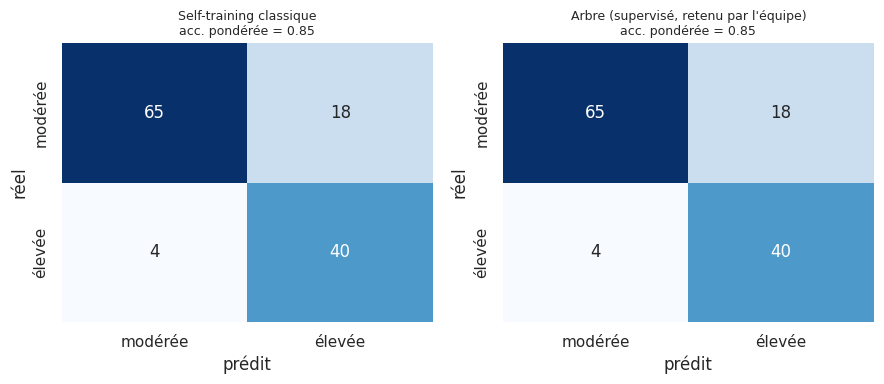

In [20]:
fig, axes = plt.subplots(1, len(NOMS_TEST), figsize=(4.5 * len(NOMS_TEST), 4))
for ax, nom in zip(np.atleast_1d(axes), NOMS_TEST):
    p = preds_test[preds_test["methode"] == nom]
    cm = ssl.confusion_matrix(p["y"], p["y_pred"], labels=[0, 1])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["modérée", "élevée"], yticklabels=["modérée", "élevée"])
    ax.set_title(f"{nom}\nacc. pondérée = {recap_test.loc[nom, 'Accuracy_ponderee']:.2f}", fontsize=9)
    ax.set_xlabel("prédit"); ax.set_ylabel("réel")
plt.tight_layout(); savefig("confusion_test"); plt.show()

In [21]:
# Le test est-il représentatif ? Répartition des soudures de test par publication, et erreurs par modèle
erreurs = (preds_test.assign(erreur=lambda d: (d["y"] != d["y_pred"]).astype(int))
           .pivot_table(index="groupe", columns="methode", values="erreur", aggfunc="sum")[NOMS_TEST])
compo = preds_test[preds_test["methode"] == NOM_RETENU].groupby("groupe")["y"].agg(
    n="size", resistance_elevee=lambda s: int((s == 1).sum()))
compo.join(erreurs.add_prefix("erreurs : ")).sort_values("n", ascending=False)

,n,resistance_elevee,erreurs : Self-training classique,"erreurs : Arbre (supervisé, retenu par l'équipe)"
groupe,,,,
Evans-Ti/Mn-1992,40,0,10,10
Evans-StressRelief-1991,16,1,3,3
Evans-AlEl9Cr1Mo-1994,13,13,0,0
Es-Souni&-Cu/CMn-1990,12,2,0,0
Kluket-CuMnB-1994,12,11,1,1
Ga&K-1975,9,8,1,1
p31-RR8201,2,2,2,2
p33-RR8201,2,0,0,0
p34-RR8201,2,2,2,2


In [22]:
# Pour information : score publié par le notebook 5 (imputation apprise sur le train seul, sans standardisation)
publie = pd.read_csv(P_REF / METHODE_REF / "test_recap_metriques.csv", sep=";", encoding="utf-8-sig", index_col=0)
publie

,CV (nouveaux découpages),Test,Baseline sur le test
Accuracy_ponderee,0.848067,0.846112,0.5
F1,0.796953,0.784314,0.0
Precision,0.787340,0.689655,0.0
Recall,0.820874,0.909091,0.0
ROC_AUC,0.871544,0.907174,0.5


### 6.1 Analyse de l'évaluation finale

**La règle fixée à l'avance retient le self-training classique**, mais à **égalité parfaite** avec le self-training équilibré et l'arbre de l'équipe (0,847 en validation croisée imbriquée : les trois font les mêmes prédictions). Son gain est nul, donc **non significatif**.

**Sur le test, les résultats confirment** : self-training classique et arbre de l'équipe obtiennent **exactement le même score** (accuracy pondérée 0,846, F1 classe élevée 0,784), identique au score publié par le notebook 5 (0,846) : notre pipeline reproduit bien le travail de l'équipe. Les erreurs se concentrent dans la publication *Evans-Ti/Mn-1992* (10 erreurs sur 40 soudures).

**Lecture complémentaire (non décisionnelle)** : sur le test, le label spreading obtient 0,852, légèrement plus que l'arbre, alors qu'il est nettement moins bon en validation croisée (0,57). Avec 127 soudures de test, cet écart n'est pas interprétable (IC [0,63 ; 0,95]) : c'est précisément pourquoi la décision est prise en validation croisée et non sur le test.

**Prédictions sur les soudures non étiquetées** (section 7) : environ **52 %** sont prédites « résistance élevée », contre 35 % parmi les étiquetées. Les soudures sans essai de traction complet sont donc en moyenne **plus alliées** que celles qui en ont un : elles ne sont pas tirées au hasard (manquants MAR, comme vu dans le préprocessing), ce qui limite aussi ce que le semi-supervisé peut en tirer.

**Décision** : on conserve l'**arbre de décision supervisé de l'équipe** pour le profil de résistance. Le semi-supervisé ne l'améliore pas avec toutes les étiquettes ; il n'aide que lorsque les étiquettes sont rares, ce qui n'est pas le cas ici. Cette recommandation est enregistrée dans le JSON.

## 7. Sauvegarde (`05_reporting/semi_supervise/profil_resistance/`)

Mêmes fichiers que pour `Charpy conforme` (notebook 6) :
- `modele_retenu_ssl.json` : méthode retenue et ses hyperparamètres, modèle de l'équipe, gains appariés, vérification des hypothèses, scores CV et test, paramètres du protocole ;
- `modele_final_ssl.joblib` : prétraitement + modèle retenu entraînés sur tout le train (+ $U$), réutilisables sans ré-entraîner ;
- CSV : prédictions hors-pli, scores par méthode et par fraction, prédictions du test ;
- `predictions_non_etiquetees.csv` : profil de résistance prédit (0 = modérée, 1 = élevée, et la probabilité d'un profil élevé) pour **chaque soudure sans étiquette** de la base, par le modèle recommandé (arbre de l'équipe) et par le semi-supervisé retenu ; `ligne_df` renvoie à la ligne de `welddb_processed_vf.csv`, et `utilisee_en_apprentissage` vaut `False` pour les soudures des publications du test (écartées de $U$) ;
- réglage : prédictions de la validation croisée imbriquée, configurations choisies par pli, scores internes du réglage final.


In [23]:
def params_modele(est):
    '''Hyperparamètres utiles d'une méthode (on ne garde que les valeurs simples).'''
    p = est.get_params(deep=False)
    out = {k: v for k, v in p.items() if isinstance(v, (int, float, str, bool, type(None)))}
    if "estimator" in p:
        out["modele_de_base"] = NOM_REF
    if hasattr(est, "steps"):
        out = {f"{n}__{k}": v for n, s in est.steps for k, v in s.get_params(deep=False).items()
               if isinstance(v, (int, float, str, bool, type(None)))}
    return out

infos = {
    "cible": CIBLE,
    "definition_cible": "profil de résistance : ACP (2 composantes) + K-means (2 groupes) sur les 4 propriétés de traction standardisées, appris sur le train — notebooks 4 et 5 ; 0 = modérée, 1 = élevée",
    "type": "classification semi-supervisée",
    "score_de_selection": METRIQUE,
    "regle_de_choix": "meilleure accuracy pondérée en CV imbriquée (hyperparamètres réglés) à 100 % des étiquettes ; utile si la borne basse de l'IC95 du gain apparié > 0",
    "modele_retenu": NOM_RETENU,
    "famille": famille,
    "hyperparametres_retenu": params_modele(methodes_finales[NOM_RETENU][0]),
    "hyperparametres_regles_retenu": meilleurs_final.get(NOM_RETENU, {}),
    "reglage": "validation croisée imbriquée : 5 plis externes (évaluation) x 3 plis internes (réglage), groupés par publication",
    "grilles": {k: v for k, v in ssl.GRILLES_CLASSIFICATION.items()},
    "modele_equipe": {"nom": NOM_REF, "hyperparametres": ref["hyperparametres_retenu"],
                      "source": str(P_REF / METHODE_REF / "modele_retenu.json")},
    "gain_cv_vs_modele_equipe": {k: g_ret[k] for k in ["gain", "IC95_bas", "IC95_haut", "P(gain > 0)"]},
    "gain_significatif": UTILE,
    "score_cv_imbriquee": scores_n.to_dict(orient="index"),
    "ic95_cv_imbriquee": {m: list(v) for m, v in ic_n.items()},
    "gains_cv_imbriquee": gains_n.set_index("semi-supervisé")[["gain", "IC95_bas", "IC95_haut", "P(gain > 0)"]].to_dict(orient="index"),
    "score_cv_sans_reglage": s100.drop(columns=[f"{METRIQUE} IC95"]).to_dict(orient="index"),
    "hyperparametres_toutes_methodes": {n: params_modele(e) for n, (e, _) in methodes_finales.items()},
    "score_test": recap_test.drop(columns="rôle").to_dict(orient="index"),
    "recommandation": (f"{NOM_RETENU} (semi-supervisé)" if UTILE and
                       recap_test.loc[NOM_RETENU, METRIQUE] >= recap_test.loc[NOM_REF_LONG, METRIQUE]
                       else f"{NOM_REF} supervisé (notebook 5) : aucun gain semi-supervisé significatif en CV"
                            + ("" if recap_test.loc[NOM_RETENU, METRIQUE] >= recap_test.loc[NOM_REF_LONG, METRIQUE]
                               else ", et le semi-supervisé retenu est moins bon sur le test")),
    "n_etiquetees_train": int(len(y_tr)), "n_etiquetees_test": int(len(y_te)),
    "n_non_etiquetees": int(len(jeux["X_unl"])), "n_non_etiquetees_exclues_test": jeux["n_unl_exclues_test"],
    "variables_utilisees": jeux["X_lab"].columns.tolist() + ["CE_IIW", "courant"],
    "verification_hypotheses": hypotheses.to_dict(),
    "RANDOM_STATE": RANDOM_STATE, "N_FOLDS": N_FOLDS, "FRACTIONS": FRACTIONS,
    "N_TIRAGES": N_TIRAGES, "N_BOOT": N_BOOT,
    "split": str(P_REF / "split_train_test.csv"),
}
# Profil de résistance prédit sur les soudures sans étiquette (modèle recommandé + semi-supervisé retenu)
preds_unl = ssl.predire_non_etiquetees(df, masque_profil, jeux, COLONNES_A_RETIRER, prep_test,
                                       {n: modeles_test[n] for n in NOMS_TEST}, nom_cible=CIBLE)
dossier = ssl.enregistrer_ssl(P_SORTIE, infos, preds_cv, scores, preds_test,
                              modeles_test[NOM_RETENU], prep_test, preds_unl)
# Fichiers du réglage imbriqué
preds_n.to_csv(dossier / "cv_imbriquee_predictions.csv", index=False, **ssl.CSV)
choix_n.assign(parametres=choix_n["parametres"].astype(str)).to_csv(dossier / "cv_imbriquee_choix_par_pli.csv", index=False, **ssl.CSV)
reglage_final.assign(parametres=reglage_final["parametres"].astype(str)).to_csv(dossier / "reglage_final_scores_internes.csv", index=False, **ssl.CSV)
print("Enregistré dans", dossier)
print(sorted(p.name for p in dossier.iterdir()))
print("\nSoudures sans étiquette : part prédite en résistance élevée (1)")
print(preds_unl[[c for c in preds_unl.columns if c.startswith(f"{CIBLE} prédit")]].mean().round(3).to_string())


Enregistré dans ../1. Données/05_reporting/semi_supervise/profil_resistance
['cv_imbriquee_choix_par_pli.csv', 'cv_imbriquee_predictions.csv', 'cv_predictions.csv', 'cv_scores_par_methode_et_fraction.csv', 'modele_final_ssl.joblib', 'modele_retenu_ssl.json', 'predictions_non_etiquetees.csv', 'reglage_final_scores_internes.csv', 'test_predictions.csv']

Soudures sans étiquette : part prédite en résistance élevée (1)
Profil de résistance prédit (Self-training classique)                   0.518
Profil de résistance prédit (Arbre (supervisé, retenu par l'équipe))    0.518


## 8. Conclusion

**Ce que montre ce notebook**
- Les hypothèses du semi-supervisé sont **moins bien vérifiées que pour `Charpy conforme`** : la lissité entre publications est plus faible (72 % contre 55 % au hasard), et dans l'espace de toutes les entrées les deux profils sont mélangés, car le profil dépend surtout de la teneur en éléments d'alliage (carbone équivalent, niobium).
- **Le self-training apporte un petit gain statistiquement significatif quand les étiquettes sont rares** (+0,02 à +0,03 avec 25 % des étiquettes, et +0,02 à 50 % pour la version équilibrée). C'est le comportement prévu par la théorie, et le seul gain établi dans nos deux études semi-supervisées.
- **Avec toutes les étiquettes, aucun gain** : le self-training ré-entraîne un arbre de profondeur 2 sur ses propres décisions et retrouve les mêmes coupures. Le label spreading et le CEM, fondés sur des distances où toutes les variables pèsent autant, sont **significativement moins bons** que l'arbre.
- Sur le test, le self-training retenu et l'arbre de l'équipe font **exactement les mêmes prédictions** (0,846). On conserve donc l'**arbre de l'équipe**.

**Comparaison avec `Charpy conforme` (notebook 6)** : dans les deux cas, le semi-supervisé ne bat pas le modèle supervisé de l'équipe avec toutes les étiquettes. Mais les raisons diffèrent : pour Charpy, le meilleur modèle en validation croisée (CEM) ne se généralise pas au test ; pour le profil de résistance, le modèle de l'équipe est si simple que le self-training ne peut pas le modifier, et les méthodes à base de distances ne capturent pas la structure du problème.

**Pistes d'amélioration**
1. Utiliser un modèle de base **plus riche** pour le self-training (forêt aléatoire, XGBoost) : un arbre de profondeur 2 ne peut pas exploiter ses pseudo-étiquettes.
2. Construire le graphe du label spreading et les gaussiennes du CEM sur les **variables qui déterminent le profil** (carbone équivalent, éléments d'alliage, traitement thermique) plutôt que sur toutes les entrées.
3. Exploiter les 149 non-étiquetées qui ont **une partie** des propriétés de traction (par exemple la limite d'élasticité seule), qui contiennent une information partielle sur leur profil.


